In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline



df = pd.read_csv("dataset_09.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (9194, 42)
   0  tcp ftp_data   SF  491   0.1  0.2  0.3  0.4  0.5  ...     25  0.17  \
0  0  udp    other   SF  146     0    0    0    0    0  ...    1.0  0.00   
1  0  tcp  private   S0    0     0    0    0    0    0  ...   26.0  0.10   
2  0  tcp     http   SF  232  8153    0    0    0    0  ...  255.0  1.00   
3  0  tcp     http   SF  199   420    0    0    0    0  ...  255.0  1.00   
4  0  tcp  private  REJ    0     0    0    0    0    0  ...   19.0  0.07   

   0.03  0.17.1  0.25  0.26  0.27  0.05  0.28   normal  
0  0.60    0.88  0.00  0.00  0.00   0.0  0.00   normal  
1  0.05    0.00  0.00  1.00  1.00   0.0  0.00  neptune  
2  0.00    0.03  0.04  0.03  0.01   0.0  0.01   normal  
3  0.00    0.00  0.00  0.00  0.00   0.0  0.00   normal  
4  0.07    0.00  0.00  0.00  0.00   1.0  1.00  neptune  

[5 rows x 42 columns]


In [ ]:
df.dropna(inplace=True)  # Drop rows with missing values

In [ ]:

X = df.iloc[:, :-1]


y = df.iloc[:, -1]


In [ ]:

categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 38
Categorical columns: 3


In [ ]:

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


model = Pipeline([
    ("preprocessing", preprocessor),
    ("kmeans", KMeans(n_clusters=2, random_state=42, n_init=10))
])


clusters = model.fit_predict(X)


df["Cluster"] = clusters



print(df["Cluster"].value_counts())

Cluster
0    6579
1    2614
Name: count, dtype: int64


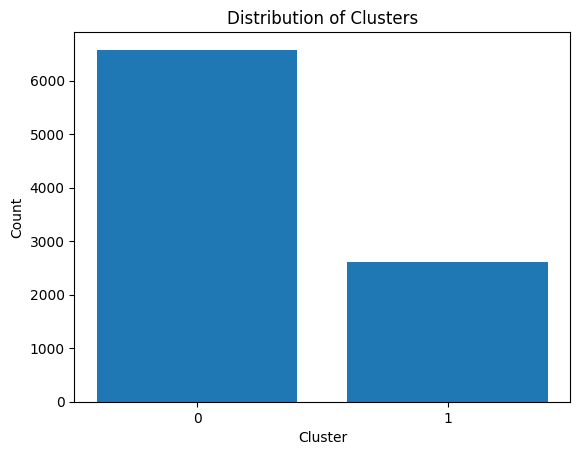

In [ ]:
cluster_counts = df["Cluster"].value_counts()
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.xlabel("Cluster")
plt.ylabel("Count")
plt.title("Distribution of Clusters")
plt.show()